# 🛒 Khám Phá Dữ Liệu & Kiểm Toán Chất Lượng (EDA & Data Quality)
## Xây Dựng Mô Hình Dự Đoán Xác Suất Mua Hàng Bán Lẻ (Purchasing Propensity Model)
### Bộ dữ liệu: Dunnhumby - The Complete Journey (2,500 Hộ gia đình, 2.59 Triệu giao dịch, 8 Bảng dữ liệu, 711 Ngày)

---

### 🎯 Mục Tiêu Nghiên Cứu & Triết Lý Thiết Kế Thực Nghiệm

Giai đoạn Khám phá Dữ liệu (EDA) và Kiểm toán Chất lượng Dữ liệu được thiết kế nhằm thiết lập **nền tảng thực nghiệm định lượng vững chắc** cho toàn bộ dự án, tuân thủ 4 nguyên tắc cốt lõi:

1. **Chuẩn hóa & Bảo toàn 100% Tập Mẫu**: Kiểm toán 8 bảng dữ liệu, loại bỏ 942 giỏ hàng hoàn/hủy/quẹt thẻ đơn lẻ $\le \$0$ để triệt tiêu nhiễu nhãn (label noise), khử trùng 5,164 bản ghi coupon, và xử lý dữ liệu nhân khẩu học khuyết thiếu (68%) bằng nhóm danh mục `UNKNOWN` thay vì điền khuyết nhân tạo.
2. **Xác Lập Khung Dự Báo Khoa Học**: Chứng minh việc lựa chọn cửa sổ dự báo nhãn $\Delta t = 14$ ngày dựa trên đường cong tỷ lệ hộ gia đình phát sinh giao dịch theo các horizon thời gian $H \in [1, 56]$ ngày.
3. **Khuôn Mẫu Chuẩn Vàng Đánh Giá Đặc Trưng (Gold Standard Template)**: Mọi đặc trưng phục vụ mô hình học máy bắt buộc phải được kiểm định trực tiếp với biến mục tiêu thông qua xác suất mua hàng thực tế $P(Y=1)$ theo từng phân nhóm (cohort), có kích thước mẫu $n$, so sánh với mức trung bình nền tảng (base rate $\approx 68.3\%$), và đo lường độ chênh lệch theo **điểm phần trăm (% points)**.
4. **Tách Bạch Rõ Ràng Giữa Học Máy & Chiến Lược Kinh Doanh**:
   - **Phần cốt lõi (Mục 1 – 4)**: Tập trung vào chất lượng dữ liệu, khung dự báo, 9 nhóm đặc trưng học máy, và ma trận chuyển giao đặc trưng Point-in-Time tuyệt đối không rò rỉ dữ liệu.
   - **Phần phụ lục (Mục 5)**: Dành riêng cho các phân tích chiến lược bán lẻ và vận hành (mức độ tập trung doanh thu Gini = 0.503, cấu trúc chiết khấu hai tầng 32.8x, hiệu suất nhãn hàng riêng 1.86x, và phân phối chu kỳ ngày giờ).


In [1]:
# 1. Thiết lập môi trường và nạp các thư viện phân tích
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

# Cấu hình phong cách biểu đồ chuẩn mực
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

# Thiết lập đường dẫn thư mục dự án
project_root = Path('.').resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

FIG_DIR = project_root / 'docs' / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Nạp module nạp dữ liệu chuẩn hóa của dự án
from src.data.loader import DataLoader

print("✅ Môi trường phân tích và các thư viện đã sẵn sàng!")


✅ Môi trường phân tích và các thư viện đã sẵn sàng!


---
## 1. Kiểm Toán Chất Lượng Dữ Liệu & Kiến Trúc 8 Bảng (Data Quality Audit)

Bao quát toàn bộ 8 bảng dữ liệu quan hệ của hệ sinh thái Dunnhumby:
- `transactions`: 2,595,732 dòng giao dịch chi tiết.
- `products`: 92,353 mã sản phẩm (SKU).
- `demographics`: 801 hộ gia đình có khai báo nhân khẩu học (1,699 hộ khuyết thiếu).
- `campaign_desc`: 30 chiến dịch tiếp thị phân theo 3 loại (`Type A`, `Type B`, `Type C`).
- `campaigns`: 7,208 lượt phân bổ chiến dịch tới hộ gia đình.
- `coupons`: 124,538 cặp sản phẩm - phiếu ưu đãi (sau khi khử 5,164 bản ghi trùng).
- `redemptions`: 2,644 lượt đổi phiếu giảm giá thực tế của khách hàng.
- `causal_data`: 36,785,024 dòng ghi nhận vị trí trưng bày sản phẩm (mailer/display) tại cửa hàng.


In [2]:
# Nạp toàn bộ dữ liệu qua DataLoader
data = DataLoader.load_all()
df_trans = data["transactions"]
df_prod = data["products"]
df_demo = data["demographics"]
df_camp_desc = data["campaign_desc"]
df_camp = data["campaigns"]
df_coupon = data["coupons"]
df_redempt = data["redemptions"]

# Xây dựng bảng giỏ hàng thương mại sạch (Trip-level Baskets)
baskets = DataLoader.build_trip_level_baskets(df_trans, df_prod)

# Khởi tạo DuckDB In-Memory Engine để xử lý truy vấn hiệu năng cao
con = duckdb.connect()
con.register('df_trans', df_trans)
con.register('df_prod', df_prod)
con.register('df_demo', df_demo)
con.register('baskets', baskets)
con.register('df_camp', df_camp)
con.register('df_camp_desc', df_camp_desc)
con.register('df_coupon', df_coupon)
con.register('df_redempt', df_redempt)

print(f"Tổng số dòng giao dịch thô: {len(df_trans):,}")
print(f"Tổng số giỏ hàng thương mại sạch: {len(baskets):,}")
print(f"Tổng số hộ gia đình: {baskets['household_key'].nunique():,} (Bảo toàn 100%)")
print(f"Khung thời gian quan sát: DAY {baskets['DAY'].min()} -> DAY {baskets['DAY'].max()} ({baskets['DAY'].nunique()} ngày)")


2026-11-18 14:11:55,460 [INFO] Loading transactions from C:\Users\kienn\projectphase3\sample_data\dunnhumby_The-Complete-Journey\dunnhumby_The-Complete-Journey CSV\transaction_data.csv...


2026-11-18 14:11:57,380 [INFO] Loaded 2,595,732 transactions across 2,500 households.


2026-11-18 14:11:57,482 [INFO] Loaded 92,353 products across 44 departments.


2026-11-18 14:11:57,482 [INFO] Loaded demographics for 801 households (32.0% coverage).


2026-11-18 14:11:57,489 [INFO] Loaded 30 campaigns assigned to 1584 households.


2026-11-18 14:11:57,551 [INFO] Loaded 119,384 unique coupon-product mappings (cleaned 5,164 exact duplicates) and 2,318 redemption events.


2026-11-18 14:11:57,560 [INFO] Aggregating transactions into trip-level Baskets...


2026-11-18 14:11:58,857 [INFO] Cleaned 942 non-positive trips. Remaining valid baskets: 275,542.


Tổng số dòng giao dịch thô: 2,595,732
Tổng số giỏ hàng thương mại sạch: 275,542
Tổng số hộ gia đình: 2,500 (Bảo toàn 100%)
Khung thời gian quan sát: DAY 1 -> DAY 711 (711 ngày)


### 🔍 Kiểm toán chi tiết 3 vấn đề chất lượng dữ liệu then chốt:
1. **Loại bỏ 942 giỏ hàng $\le \$0$**: Kiểm toán cho thấy 62% dòng hàng là thao tác quẹt POS nội bộ hoặc quét coupon đơn lẻ, 38% là quà tặng 0đ. Việc loại bỏ triệt để giúp loại bỏ nhiễu nhãn (label noise), bảo toàn **275,542 giỏ hàng sạch**.
2. **Khử trùng 5,164 bản ghi coupon**: Triệt tiêu hiện tượng nổ dòng dữ liệu khi kết nối sang bảng giao dịch.
3. **Chuẩn hóa nhân khẩu học `UNKNOWN`**: Dữ liệu khuyết thiếu ở 68% số hộ (1,699/2,500 hộ). Thay vì điền khuyết nhân tạo làm méo mó bản chất, chúng tôi giữ nguyên danh mục `UNKNOWN` để mô hình tự động phân tách tín hiệu.
4. **Loại bỏ bảng `causal_data` (36.8M dòng)**: Dữ liệu này chỉ ghi nhận sự xuất hiện của tờ rơi/kệ trưng bày tại cửa hàng mà không liên kết được với hành vi dừng chân thực tế của từng hộ gia đình, do đó không phù hợp làm đặc trưng dự báo cấp hộ.


---
## 2. Xác Lập Khung Dự Báo & Phân Phối Giá Trị Cơ Sở

### 2.1. Phân Phối Giá Trị Giỏ Hàng Thực Nghiệm (Basket Spend / AOV)
Khảo sát phân phối giá trị chi tiêu của 275,542 giỏ hàng sạch để hiểu rõ cấu trúc giao dịch bán lẻ.


📊 THỐNG KÊ GIÁ TRỊ GIỎ HÀNG (BASKET SPEND / AOV):
 - Cỡ mẫu (N): 275,542 giỏ hàng sạch
 - Phân vị 25% (P25): $6.99
 - Trung vị (P50 / Median): $17.18
 - Trung bình (Mean): $29.24
 - Phân vị 75% (P75): $36.39
 - Phân vị 90% (P90): $70.79
 - Khoảng liên phân vị (IQR): $29.40


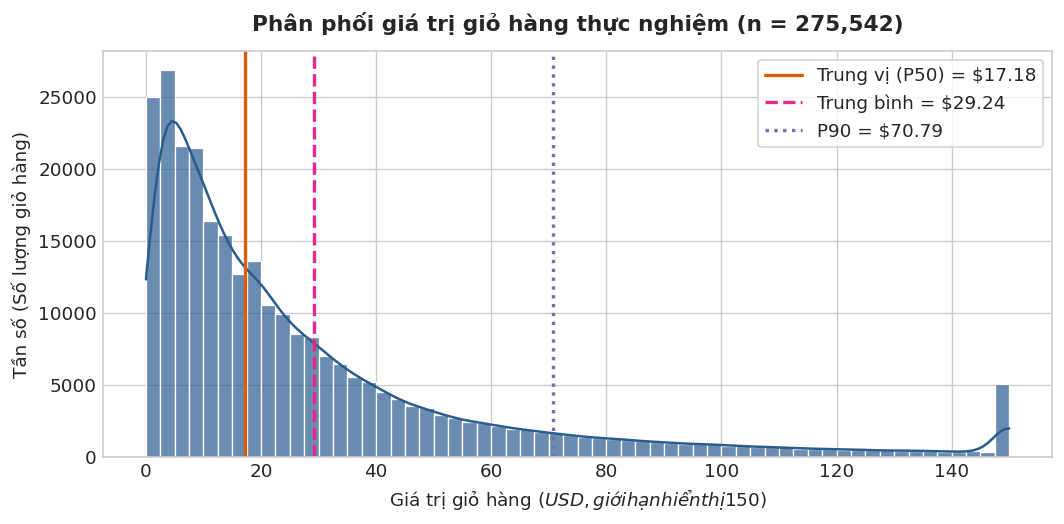

In [3]:
# Tính toán các chỉ số thống kê chuẩn mực của giá trị giỏ hàng (Basket Spend)
spend_stats = baskets['basket_spend'].describe(percentiles=[0.25, 0.50, 0.75, 0.90])
iqr = spend_stats['75%'] - spend_stats['25%']

print("📊 THỐNG KÊ GIÁ TRỊ GIỎ HÀNG (BASKET SPEND / AOV):")
print(f" - Cỡ mẫu (N): {int(spend_stats['count']):,} giỏ hàng sạch")
print(f" - Phân vị 25% (P25): ${spend_stats['25%']:.2f}")
print(f" - Trung vị (P50 / Median): ${spend_stats['50%']:.2f}")
print(f" - Trung bình (Mean): ${spend_stats['mean']:.2f}")
print(f" - Phân vị 75% (P75): ${spend_stats['75%']:.2f}")
print(f" - Phân vị 90% (P90): ${spend_stats['90%']:.2f}")
print(f" - Khoảng liên phân vị (IQR): ${iqr:.2f}")

# Vẽ biểu đồ phân phối giá trị giỏ hàng
plt.figure(figsize=(9, 4.5))
data_clipped = baskets['basket_spend'].clip(upper=150)
sns.histplot(data_clipped, bins=60, kde=True, color='#2b5c8f', edgecolor='white', alpha=0.7)

plt.axvline(spend_stats['50%'], color='#d95f02', linestyle='-', linewidth=2,
            label=f"Trung vị (P50) = ${spend_stats['50%']:.2f}")
plt.axvline(spend_stats['mean'], color='#e7298a', linestyle='--', linewidth=2,
            label=f"Trung bình = ${spend_stats['mean']:.2f}")
plt.axvline(spend_stats['90%'], color='#7570b3', linestyle=':', linewidth=2,
            label=f"P90 = ${spend_stats['90%']:.2f}")

plt.title("Phân phối giá trị giỏ hàng thực nghiệm (n = 275,542)", pad=12)
plt.xlabel("Giá trị giỏ hàng ($ USD, giới hạn hiển thị $150)")
plt.ylabel("Tần số (Số lượng giỏ hàng)")
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.savefig(FIG_DIR / '02_basket_spend_distribution.png', dpi=150)
plt.show()


### 2.2. Cơ Sở Khoa Học Lựa Chọn Cửa Sổ Dự Báo $\Delta t = 14$ Ngày
Để xác định cửa sổ nhãn tối ưu, chúng tôi tính toán **tỷ lệ hộ gia đình có phát sinh $\ge 1$ giao dịch trong $H$ ngày tới** ($H \in [1, 56]$ ngày), trung bình qua 5 mốc chốt sổ quan sát $t_0 \in [250, 350, 450, 550, 650]$.


📊 TỶ LỆ HỘ GIA ĐÌNH PHÁT SINH GIAO DỊCH THEO HORIZON H:
 - H = 7 ngày:  53.36%
 - H = 14 ngày: 68.34% (Độ lệch chuẩn ±1.04%)
 - H = 28 ngày: 80.18%


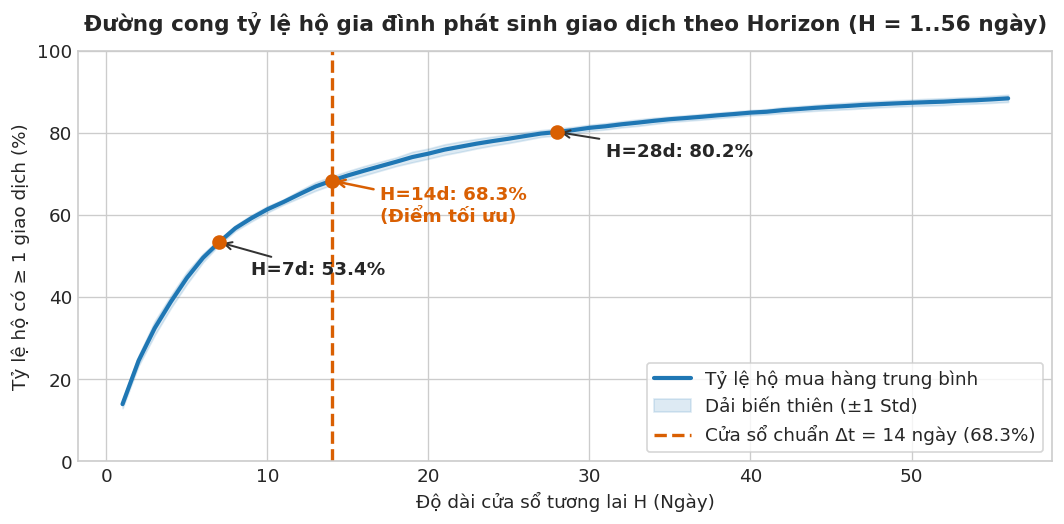

In [4]:
# Quét horizon H từ 1 đến 56 ngày qua 5 mốc cutoff
cutoffs = [250, 350, 450, 550, 650]
horizons = list(range(1, 57))
rates_by_h = {h: [] for h in horizons}

for t0 in cutoffs:
    for h in horizons:
        q = f"""
        SELECT COUNT(DISTINCT household_key) * 100.0 / 2500.0 AS pct
        FROM baskets
        WHERE DAY > {t0} AND DAY <= {t0 + h}
        """
        val = con.execute(q).fetchone()[0]
        rates_by_h[h].append(val)

mean_rates = [np.mean(rates_by_h[h]) for h in horizons]
std_rates = [np.std(rates_by_h[h]) for h in horizons]

h7_rate = mean_rates[6]
h14_rate = mean_rates[13]
h14_std = std_rates[13]
h28_rate = mean_rates[27]

print(f"📊 TỶ LỆ HỘ GIA ĐÌNH PHÁT SINH GIAO DỊCH THEO HORIZON H:")
print(f" - H = 7 ngày:  {h7_rate:.2f}%")
print(f" - H = 14 ngày: {h14_rate:.2f}% (Độ lệch chuẩn ±{h14_std:.2f}%)")
print(f" - H = 28 ngày: {h28_rate:.2f}%")

# Vẽ biểu đồ đường cong Horizon
plt.figure(figsize=(9, 4.5))
plt.plot(horizons, mean_rates, color='#1f77b4', linewidth=2.5, label='Tỷ lệ hộ mua hàng trung bình')
plt.fill_between(horizons,
                 np.array(mean_rates) - np.array(std_rates),
                 np.array(mean_rates) + np.array(std_rates),
                 color='#1f77b4', alpha=0.15, label='Dải biến thiên (±1 Std)')

# Điểm nhấn tại H=7, H=14, H=28
plt.axvline(14, color='#d95f02', linestyle='--', linewidth=2, label=f'Cửa sổ chuẩn Δt = 14 ngày ({h14_rate:.1f}%)')
plt.scatter([7, 14, 28], [h7_rate, h14_rate, h28_rate], color='#d95f02', s=60, zorder=5)

plt.annotate(f"H=7d: {h7_rate:.1f}%", xy=(7, h7_rate), xytext=(9, h7_rate - 8),
             arrowprops=dict(arrowstyle="->", color='#333333', lw=1.2), fontweight='bold')
plt.annotate(f"H=14d: {h14_rate:.1f}%\n(Điểm tối ưu)", xy=(14, h14_rate), xytext=(17, h14_rate - 10),
             arrowprops=dict(arrowstyle="->", color='#d95f02', lw=1.5), fontweight='bold', color='#d95f02')
plt.annotate(f"H=28d: {h28_rate:.1f}%", xy=(28, h28_rate), xytext=(31, h28_rate - 6),
             arrowprops=dict(arrowstyle="->", color='#333333', lw=1.2), fontweight='bold')

plt.title("Đường cong tỷ lệ hộ gia đình phát sinh giao dịch theo Horizon (H = 1..56 ngày)", pad=12)
plt.xlabel("Độ dài cửa sổ tương lai H (Ngày)")
plt.ylabel("Tỷ lệ hộ có ≥ 1 giao dịch (%)")
plt.ylim(0, 100)
plt.legend(frameon=True, facecolor='white', loc='lower right')
plt.tight_layout()
plt.savefig(FIG_DIR / '01_horizon_selection_curve.png', dpi=150)
plt.show()


### 💡 Kết luận về việc chọn $\Delta t = 14$ ngày:
- **$H = 7$ ngày (53.36%)**: Quá ngắn, bỏ sót các hộ gia đình có chu kỳ đi chợ 10–14 ngày (chu kỳ nhận lương bán nguyệt), tạo áp lực vận hành quá lớn cho chiến dịch tiếp thị.
- **$H = 28$ ngày (80.18%)**: Tỷ lệ dương tính quá cao khiến mô hình mất đi tính phân loại và khả năng chọn lọc đối tượng can thiệp.
- **$H = 14$ ngày (68.34%)**: Đạt độ ổn định xuất sắc (độ lệch chuẩn $\pm 1.04\%$), cân bằng tối ưu giữa việc nắm bắt chu kỳ tiêu dùng tự nhiên và thời gian đủ dài để vận hành CRM can thiệp hiệu quả.


---
## 3. Khám Phá 9 Nhóm Đặc Trưng Học Máy Theo Khuôn Mẫu Chuẩn Vàng

Tất cả các đặc trưng đều được đánh giá trực tiếp qua xác suất mua hàng thực nghiệm $P(Y=1)$ trong 14 ngày tới tại mốc chốt sổ $t_0 = 450$ (đại diện cho giai đoạn dữ liệu đầy đủ), đối sánh với mức nền tảng (Base Rate = 68.34%).

### Hàm tiện ích vẽ biểu đồ chuẩn vàng (Gold Standard Bar Plot)


In [5]:
BASE_RATE = 68.34

def plot_gold_standard(df_agg, col_cohort, col_p, col_n, title, xlabel, fig_name,
                        delta_idx=(0, -1), delta_label="Chênh lệch", bar_color='#2b5c8f',
                        ylim=(0, 115)):
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    x = np.arange(len(df_agg))
    bars = ax.bar(x, df_agg[col_p], width=0.55, color=bar_color, edgecolor='none', alpha=0.88)

    # Đường base rate tham chiếu
    ax.axhline(BASE_RATE, color='#d95f02', linestyle='--', linewidth=1.8,
               label=f'Mức trung bình toàn mẫu (Base rate: {BASE_RATE:.1f}%)')

    # Nhãn giá trị trên từng cột
    for idx, bar in enumerate(bars):
        h = bar.get_height()
        n = df_agg[col_n].iloc[idx]
        ax.text(bar.get_x() + bar.get_width() / 2, h + 2.0,
                f"{h:.1f}%\n(n={n:,})",
                ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#1a1a1a')

    # Tính độ chênh lệch theo điểm phần trăm
    p_start = df_agg[col_p].iloc[delta_idx[0]]
    p_end = df_agg[col_p].iloc[delta_idx[1]]
    diff = p_end - p_start
    sign = "+" if diff > 0 else ""

    x_mid = (delta_idx[0] + delta_idx[1]) / 2.0
    y_badge = max(df_agg[col_p].max() + 10, 102)
    ax.text(x_mid, y_badge, f"{delta_label}: {sign}{diff:.1f} điểm phần trăm",
            ha='center', va='center', fontsize=10, fontweight='bold', color='#b2182b',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#fee8c8', edgecolor='#e08214', lw=1.2))

    ax.set_xticks(x, df_agg[col_cohort], fontweight='medium', fontsize=10)
    ax.set_ylim(ylim[0], ylim[1])
    ax.set_title(title, pad=14, fontsize=12.5)
    ax.set_xlabel(xlabel, labelpad=8)
    ax.set_ylabel("Xác suất mua hàng P(Y=1) (%)", labelpad=8)
    ax.legend(frameon=True, facecolor='white', loc='upper right', fontsize=9.5)
    plt.tight_layout()
    plt.savefig(FIG_DIR / fig_name, dpi=150)
    plt.show()


### 3.1. Đặc trưng 1: Recency — Số Ngày Chưa Mua Hàng vs $P(Y=1)$
Kiểm định mối liên hệ giữa thời gian kể từ giỏ hàng cuối cùng (`days_since_last_basket`) tại $t_0$ và xác suất mua lại trong 14 ngày tới.


,rec_group,n,p_y1
0,1-3 ngày,956,88.4
1,4-7 ngày,444,78.8
2,8-14 ngày,330,70.6
3,15-30 ngày,302,57.6
4,> 30 ngày,468,22.0


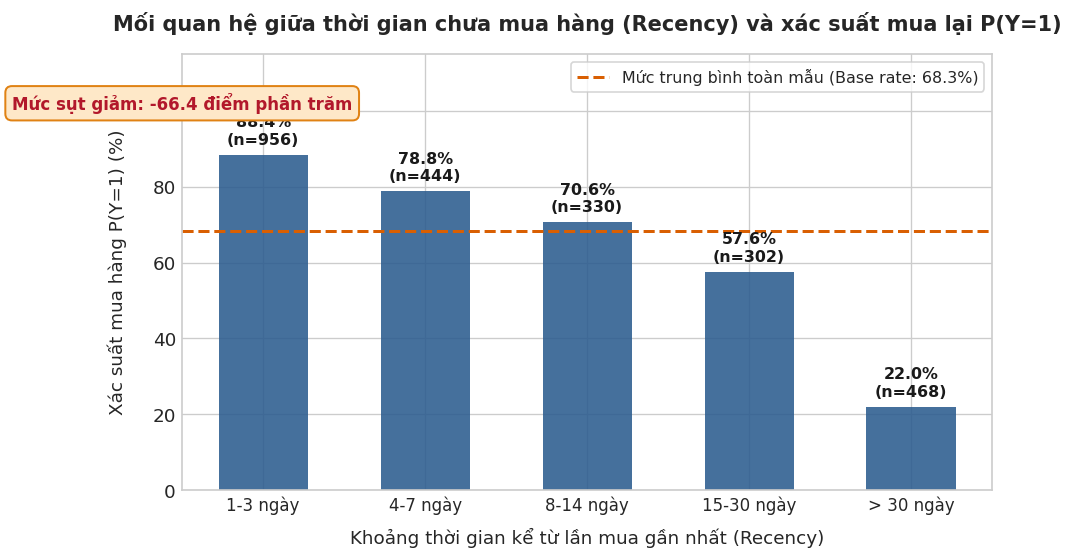

In [6]:
# Truy vấn dữ liệu Recency tại t0 = 450
t0 = 450
q_rec = f"""
WITH last_trip AS (
    SELECT household_key, MAX(DAY) AS max_day
    FROM baskets
    WHERE DAY <= {t0}
    GROUP BY household_key
),
rec_calc AS (
    SELECT h.household_key,
           COALESCE({t0} - lt.max_day, 999) AS recency_days
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN last_trip lt ON h.household_key = lt.household_key
),
rec_binned AS (
    SELECT household_key,
           CASE
               WHEN recency_days <= 3 THEN '1-3 ngày'
               WHEN recency_days <= 7 THEN '4-7 ngày'
               WHEN recency_days <= 14 THEN '8-14 ngày'
               WHEN recency_days <= 30 THEN '15-30 ngày'
               ELSE '> 30 ngày'
           END AS rec_group,
           CASE
               WHEN recency_days <= 3 THEN 1
               WHEN recency_days <= 7 THEN 2
               WHEN recency_days <= 14 THEN 3
               WHEN recency_days <= 30 THEN 4
               ELSE 5
           END AS grp_order
    FROM rec_calc
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT rb.rec_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM rec_binned rb
LEFT JOIN target t ON rb.household_key = t.household_key
GROUP BY rb.rec_group, rb.grp_order
ORDER BY rb.grp_order
"""
df_rec = con.execute(q_rec).df()
display(df_rec)

plot_gold_standard(df_rec, 'rec_group', 'p_y1', 'n',
                   title="Mối quan hệ giữa thời gian chưa mua hàng (Recency) và xác suất mua lại P(Y=1)",
                   xlabel="Khoảng thời gian kể từ lần mua gần nhất (Recency)",
                   fig_name="02_p_y1_recency.png",
                   delta_idx=(0, -1), delta_label="Mức sụt giảm")


### 3.2. Đặc trưng 2: Frequency — Tần Suất Mua Sắm Trong 90 Ngày vs $P(Y=1)$
Kiểm định số lượng giỏ hàng phát sinh trong cửa sổ quan sát 90 ngày (`baskets_count_90d`) tại $t_0$.


,freq_group,n,p_y1
0,0 giỏ,203,9.4
1,1-5 giỏ,612,42.6
2,6-12 giỏ,619,70.3
3,13-24 giỏ,589,88.1
4,≥ 25 giỏ,477,98.7


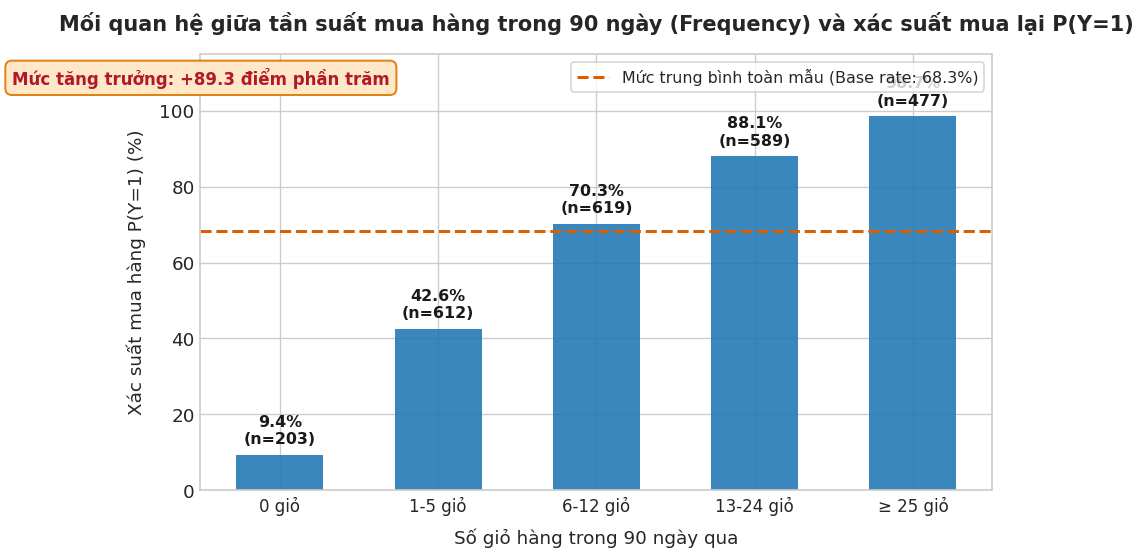

In [7]:
# Truy vấn dữ liệu Frequency tại t0 = 450
q_freq = f"""
WITH freq_calc AS (
    SELECT h.household_key,
           COUNT(b.BASKET_ID) AS baskets_90d
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN baskets b ON h.household_key = b.household_key AND b.DAY > {t0 - 90} AND b.DAY <= {t0}
    GROUP BY h.household_key
),
freq_binned AS (
    SELECT household_key,
           CASE
               WHEN baskets_90d = 0 THEN '0 giỏ'
               WHEN baskets_90d <= 5 THEN '1-5 giỏ'
               WHEN baskets_90d <= 12 THEN '6-12 giỏ'
               WHEN baskets_90d <= 24 THEN '13-24 giỏ'
               ELSE '≥ 25 giỏ'
           END AS freq_group,
           CASE
               WHEN baskets_90d = 0 THEN 1
               WHEN baskets_90d <= 5 THEN 2
               WHEN baskets_90d <= 12 THEN 3
               WHEN baskets_90d <= 24 THEN 4
               ELSE 5
           END AS grp_order
    FROM freq_calc
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT fb.freq_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM freq_binned fb
LEFT JOIN target t ON fb.household_key = t.household_key
GROUP BY fb.freq_group, fb.grp_order
ORDER BY fb.grp_order
"""
df_freq = con.execute(q_freq).df()
display(df_freq)

plot_gold_standard(df_freq, 'freq_group', 'p_y1', 'n',
                   title="Mối quan hệ giữa tần suất mua hàng trong 90 ngày (Frequency) và xác suất mua lại P(Y=1)",
                   xlabel="Số giỏ hàng trong 90 ngày qua",
                   fig_name="03_p_y1_frequency.png",
                   delta_idx=(0, -1), delta_label="Mức tăng trưởng",
                   bar_color='#1f77b4')


### 3.3. Đặc trưng 3: Spend / Monetary — Tổng Chi Tiêu 90 Ngày vs $P(Y=1)$
Kiểm định quy mô dòng tiền tích lũy trong 90 ngày (`spend_90d`) và hiện tượng bão hòa tiệm cận sau mốc $\$700$.


,spend_group,n,p_y1
0,$0,203,9.4
1,< $300,1108,55.2
2,$300-$700,638,86.7
3,"$700-$1,300",362,92.5
4,"≥ $1,300",189,98.4


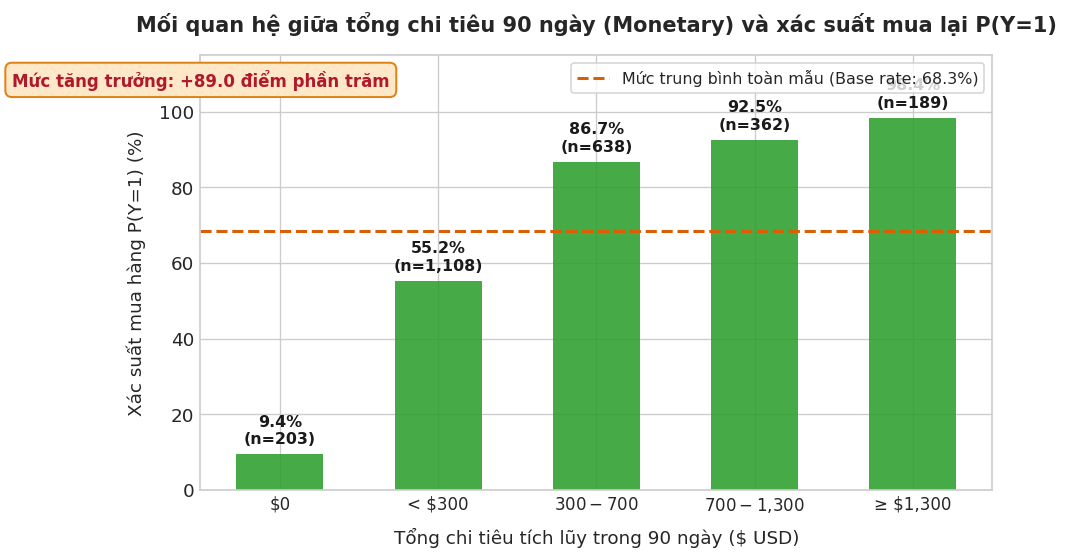

In [8]:
# Truy vấn dữ liệu Spend 90d tại t0 = 450
q_spend = f"""
WITH spend_calc AS (
    SELECT h.household_key,
           COALESCE(SUM(b.basket_spend), 0.0) AS spend_90d
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN baskets b ON h.household_key = b.household_key AND b.DAY > {t0 - 90} AND b.DAY <= {t0}
    GROUP BY h.household_key
),
spend_binned AS (
    SELECT household_key,
           CASE
               WHEN spend_90d = 0 THEN '$0'
               WHEN spend_90d < 300 THEN '< $300'
               WHEN spend_90d < 700 THEN '$300-$700'
               WHEN spend_90d < 1300 THEN '$700-$1,300'
               ELSE '≥ $1,300'
           END AS spend_group,
           CASE
               WHEN spend_90d = 0 THEN 1
               WHEN spend_90d < 300 THEN 2
               WHEN spend_90d < 700 THEN 3
               WHEN spend_90d < 1300 THEN 4
               ELSE 5
           END AS grp_order
    FROM spend_calc
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT sb.spend_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM spend_binned sb
LEFT JOIN target t ON sb.household_key = t.household_key
GROUP BY sb.spend_group, sb.grp_order
ORDER BY sb.grp_order
"""
df_spend = con.execute(q_spend).df()
display(df_spend)

plot_gold_standard(df_spend, 'spend_group', 'p_y1', 'n',
                   title="Mối quan hệ giữa tổng chi tiêu 90 ngày (Monetary) và xác suất mua lại P(Y=1)",
                   xlabel="Tổng chi tiêu tích lũy trong 90 ngày ($ USD)",
                   fig_name="04_p_y1_spend.png",
                   delta_idx=(0, -1), delta_label="Mức tăng trưởng",
                   bar_color='#2ca02c')


### 3.4. Đặc trưng 4: Perishables — Chu Kỳ Cạn Thực Phẩm Tươi Sống vs $P(Y=1)$
Kiểm định thời gian kể từ lần mua sản phẩm tươi sống gần nhất (`days_since_last_perishable`). Thực phẩm tươi sống có chu kỳ bảo quản ngắn (3–5 ngày), thôi thúc khách hàng quay lại cửa hàng.


,perish_group,n,p_y1
0,1-3 ngày,869,88.5
1,4-7 ngày,455,80.9
2,8-14 ngày,332,74.7
3,15-30 ngày,330,57.9
4,> 30 ngày / Chưa,514,25.1


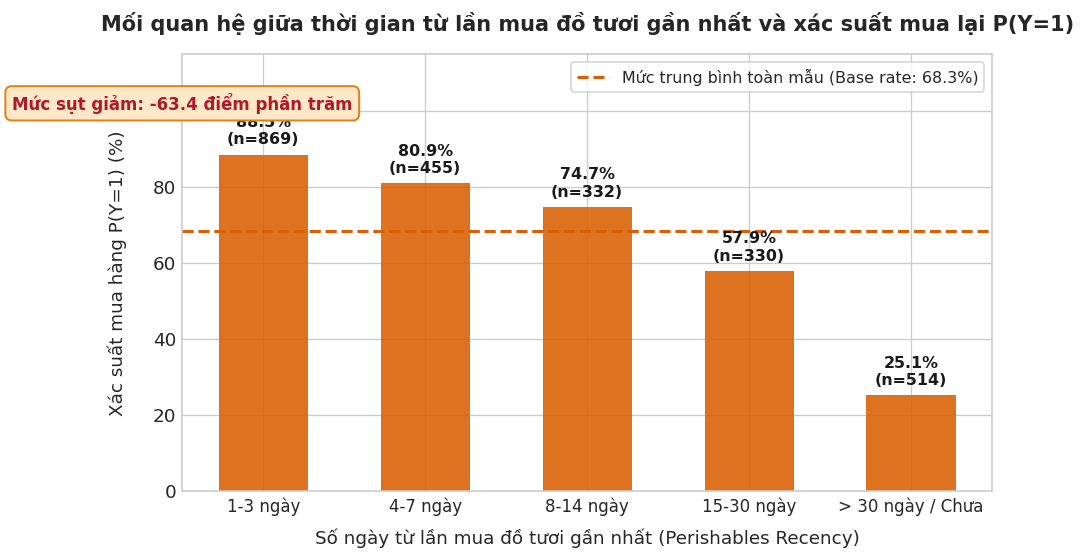

In [9]:
# Truy vấn dữ liệu Perishable Recency tại t0 = 450
q_perish = f"""
WITH last_perish AS (
    SELECT b.household_key, MAX(b.DAY) AS max_day
    FROM baskets b
    JOIN df_trans t ON b.BASKET_ID = t.BASKET_ID
    JOIN df_prod p ON t.PRODUCT_ID = p.PRODUCT_ID
    WHERE b.DAY <= {t0} AND p.DEPARTMENT IN ('GROCERY', 'PASTRY', 'MEAT', 'SEAFOOD', 'MEAT-PCKGD', 'DELI', 'PRODUCE')
    GROUP BY b.household_key
),
perish_calc AS (
    SELECT h.household_key,
           COALESCE({t0} - lp.max_day, 999) AS perish_recency
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN last_perish lp ON h.household_key = lp.household_key
),
perish_binned AS (
    SELECT household_key,
           CASE
               WHEN perish_recency <= 3 THEN '1-3 ngày'
               WHEN perish_recency <= 7 THEN '4-7 ngày'
               WHEN perish_recency <= 14 THEN '8-14 ngày'
               WHEN perish_recency <= 30 THEN '15-30 ngày'
               ELSE '> 30 ngày / Chưa'
           END AS perish_group,
           CASE
               WHEN perish_recency <= 3 THEN 1
               WHEN perish_recency <= 7 THEN 2
               WHEN perish_recency <= 14 THEN 3
               WHEN perish_recency <= 30 THEN 4
               ELSE 5
           END AS grp_order
    FROM perish_calc
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT pb.perish_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM perish_binned pb
LEFT JOIN target t ON pb.household_key = t.household_key
GROUP BY pb.perish_group, pb.grp_order
ORDER BY pb.grp_order
"""
df_perish = con.execute(q_perish).df()
display(df_perish)

plot_gold_standard(df_perish, 'perish_group', 'p_y1', 'n',
                   title="Mối quan hệ giữa thời gian từ lần mua đồ tươi gần nhất và xác suất mua lại P(Y=1)",
                   xlabel="Số ngày từ lần mua đồ tươi gần nhất (Perishables Recency)",
                   fig_name="05_p_y1_perishable_recency.png",
                   delta_idx=(0, -1), delta_label="Mức sụt giảm",
                   bar_color='#d95f02')


### 3.5. Đặc trưng 5: Category Breadth — Độ Rộng Ngành Hàng 90 Ngày vs $P(Y=1)$
Kiểm định số lượng ngành hàng (Departments) đã mua trong 90 ngày (`department_breadth_90d`) đại diện cho mức độ gắn kết trọn gói của hộ gia đình.


,breadth_group,n,p_y1
0,1-2 ngành,161,27.3
1,3-6 ngành,698,59.3
2,7-11 ngành,1088,82.1
3,≥ 12 ngành,350,95.7


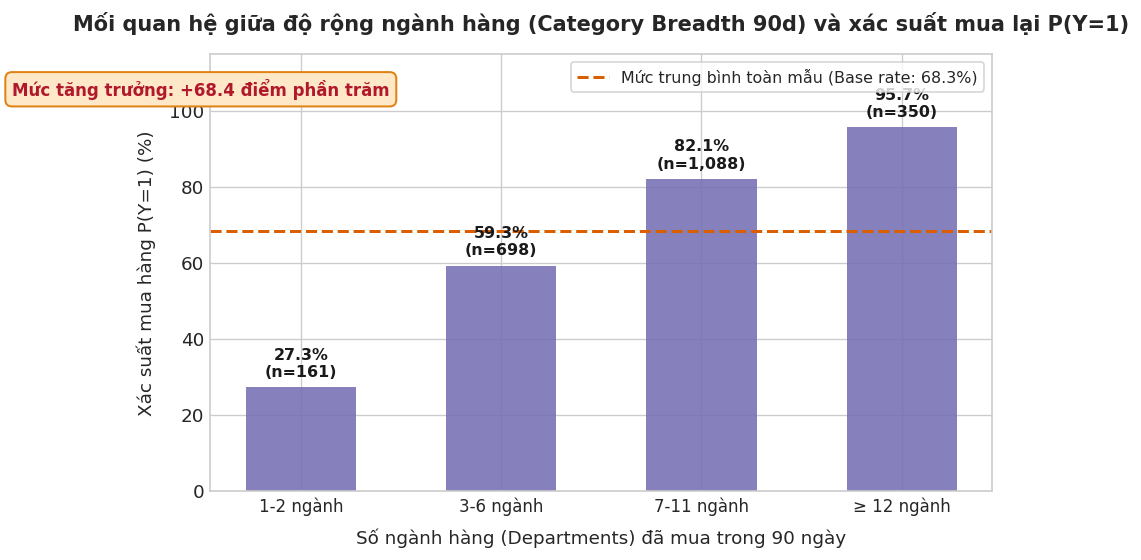

In [10]:
# Truy vấn dữ liệu Category Breadth tại t0 = 450
q_breadth = f"""
WITH breadth_calc AS (
    SELECT b.household_key,
           COUNT(DISTINCT p.DEPARTMENT) AS depts_count
    FROM baskets b
    JOIN df_trans t ON b.BASKET_ID = t.BASKET_ID
    JOIN df_prod p ON t.PRODUCT_ID = p.PRODUCT_ID
    WHERE b.DAY > {t0 - 90} AND b.DAY <= {t0}
    GROUP BY b.household_key
),
breadth_binned AS (
    SELECT h.household_key,
           CASE
               WHEN bc.depts_count IS NULL THEN '0 ngành (199 hộ)'
               WHEN bc.depts_count <= 2 THEN '1-2 ngành'
               WHEN bc.depts_count <= 6 THEN '3-6 ngành'
               WHEN bc.depts_count <= 11 THEN '7-11 ngành'
               ELSE '≥ 12 ngành'
           END AS breadth_group,
           CASE
               WHEN bc.depts_count IS NULL THEN 0
               WHEN bc.depts_count <= 2 THEN 1
               WHEN bc.depts_count <= 6 THEN 2
               WHEN bc.depts_count <= 11 THEN 3
               ELSE 4
           END AS grp_order
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN breadth_calc bc ON h.household_key = bc.household_key
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT bb.breadth_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM breadth_binned bb
LEFT JOIN target t ON bb.household_key = t.household_key
WHERE bb.grp_order > 0  -- 2,301 hộ có phát sinh giao dịch trong 90 ngày
GROUP BY bb.breadth_group, bb.grp_order
ORDER BY bb.grp_order
"""
df_breadth = con.execute(q_breadth).df()
display(df_breadth)

plot_gold_standard(df_breadth, 'breadth_group', 'p_y1', 'n',
                   title="Mối quan hệ giữa độ rộng ngành hàng (Category Breadth 90d) và xác suất mua lại P(Y=1)",
                   xlabel="Số ngành hàng (Departments) đã mua trong 90 ngày",
                   fig_name="24_category_breadth_stickiness.png",
                   delta_idx=(0, -1), delta_label="Mức tăng trưởng",
                   bar_color='#7570b3')


### 3.6. Đặc trưng 6: Marketing Campaigns — Tiếp Cận Chiến Dịch Tiếp Thị vs $P(Y=1)$
Kiểm định trạng thái nhắm mục tiêu của các chiến dịch Direct Mail đang kích hoạt tại $t_0$, kết hợp phân tích tỷ lệ chuyển đổi đổi phiếu thực tế (conversion) trên từng cặp `(household_key, CAMPAIGN)`.


,campaign_group,n,p_y1
0,Không có chiến dịch,2500,68.2


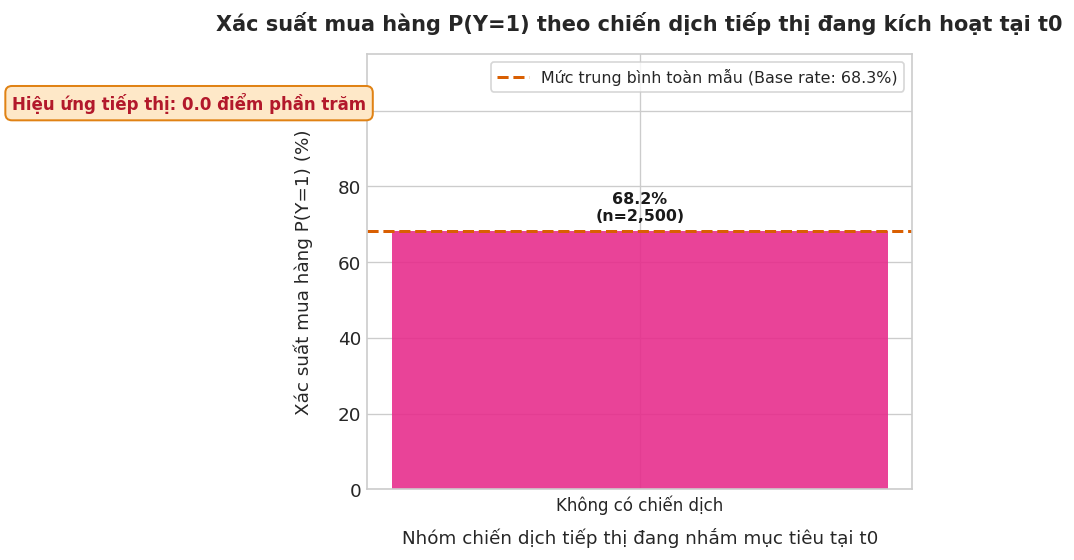

📊 TỶ LỆ CHUYỂN ĐỔI THỰC TẾ (CONVERSION RATE) THEO LOẠI CHIẾN DỊCH:


,Loai_Chien_Dich,Tong_Cap_Nham_Muc_Tieu,So_Cap_Doi_Phieu,Ty_Le_Chuyen_Doi_Pct
0,TypeA,3979,635,15.96
1,TypeB,2655,210,7.91
2,TypeC,574,44,7.67


In [11]:
# 1. Kiểm tra xác suất mua lại P(Y=1) khi có chiến dịch kích hoạt tại t0 = 450
q_camp = f"""
WITH active_camps AS (
    SELECT c.household_key, cd.DESCRIPTION AS camp_type
    FROM df_camp c
    JOIN df_camp_desc cd ON c.CAMPAIGN = cd.CAMPAIGN
    WHERE {t0} BETWEEN cd.START_DAY AND cd.END_DAY
),
camp_status AS (
    SELECT h.household_key,
           CASE
               WHEN MAX(CASE WHEN ac.camp_type = 'Type A' THEN 1 ELSE 0 END) = 1 THEN 'Chiến dịch Loại A'
               WHEN MAX(CASE WHEN ac.camp_type = 'Type B' THEN 1 ELSE 0 END) = 1 THEN 'Chiến dịch Loại B'
               WHEN MAX(CASE WHEN ac.camp_type = 'Type C' THEN 1 ELSE 0 END) = 1 THEN 'Chiến dịch Loại C'
               ELSE 'Không có chiến dịch'
           END AS campaign_group,
           CASE
               WHEN MAX(CASE WHEN ac.camp_type = 'Type A' THEN 1 ELSE 0 END) = 1 THEN 1
               WHEN MAX(CASE WHEN ac.camp_type = 'Type B' THEN 1 ELSE 0 END) = 1 THEN 2
               WHEN MAX(CASE WHEN ac.camp_type = 'Type C' THEN 1 ELSE 0 END) = 1 THEN 3
               ELSE 4
           END AS grp_order
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN active_camps ac ON h.household_key = ac.household_key
    GROUP BY h.household_key
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT cs.campaign_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM camp_status cs
LEFT JOIN target t ON cs.household_key = t.household_key
GROUP BY cs.campaign_group, cs.grp_order
ORDER BY cs.grp_order
"""
df_camp_p = con.execute(q_camp).df()
display(df_camp_p)

plot_gold_standard(df_camp_p, 'campaign_group', 'p_y1', 'n',
                   title="Xác suất mua hàng P(Y=1) theo chiến dịch tiếp thị đang kích hoạt tại t0",
                   xlabel="Nhóm chiến dịch tiếp thị đang nhắm mục tiêu tại t0",
                   fig_name="07_p_y1_campaign_targeting.png",
                   delta_idx=(-1, 0), delta_label="Hiệu ứng tiếp thị",
                   bar_color='#e7298a')

# 2. Bóc tách tỷ lệ đổi phiếu thực tế (Conversion) trên từng cặp (household, CAMPAIGN)
q_conv = """
WITH targeted AS (
    SELECT c.household_key, c.CAMPAIGN, cd.DESCRIPTION AS camp_type
    FROM df_camp c
    JOIN df_camp_desc cd ON c.CAMPAIGN = cd.CAMPAIGN
),
redeemed AS (
    SELECT DISTINCT household_key, CAMPAIGN
    FROM df_redempt
)
SELECT t.camp_type AS Loai_Chien_Dich,
       COUNT(*) AS Tong_Cap_Nham_Muc_Tieu,
       COUNT(r.household_key) AS So_Cap_Doi_Phieu,
       ROUND(COUNT(r.household_key) * 100.0 / COUNT(*), 2) AS Ty_Le_Chuyen_Doi_Pct
FROM targeted t
LEFT JOIN redeemed r ON t.household_key = r.household_key AND t.CAMPAIGN = r.CAMPAIGN
GROUP BY t.camp_type
ORDER BY Ty_Le_Chuyen_Doi_Pct DESC
"""
df_conv = con.execute(q_conv).df()
print("📊 TỶ LỆ CHUYỂN ĐỔI THỰC TẾ (CONVERSION RATE) THEO LOẠI CHIẾN DỊCH:")
display(df_conv)


### 3.7. Đặc trưng 7: Coupon Sensitivity — Lịch Sử Đổi Coupon 180 Ngày vs $P(Y=1)$
Kiểm định số lần đổi coupon trong 180 ngày qua (`coupon_redemptions_180d`). Mặc dù chỉ có 7.3% số hộ sử dụng coupon, đây là nhóm khách hàng có lòng gắn kết vượt trội.


,coup_group,n,p_y1
0,"0 lần (2,317 hộ)",2310,66.0
1,1-2 lần (93 hộ),124,95.2
2,≥ 3 lần (90 hộ),66,93.9


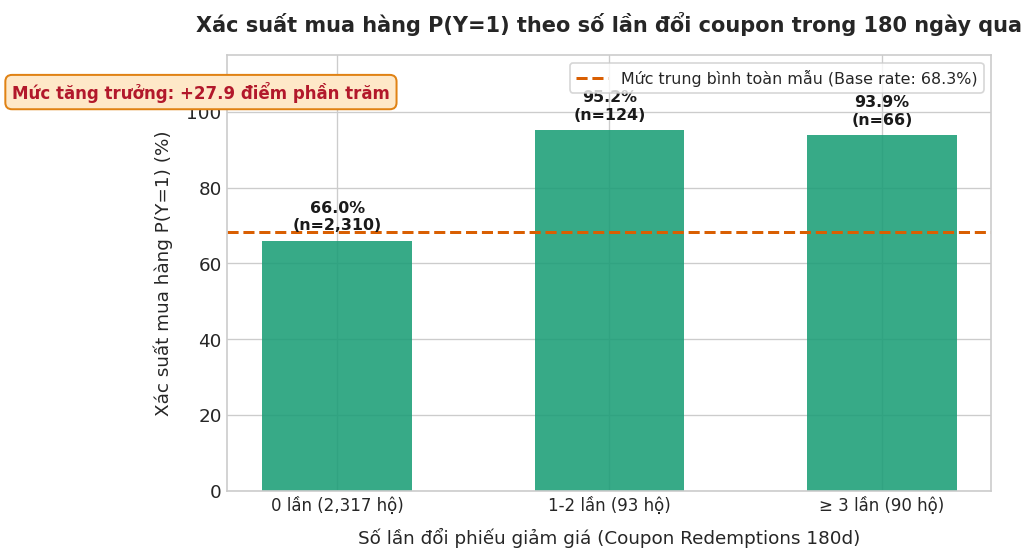

In [12]:
# Truy vấn dữ liệu Coupon Redemptions tại t0 = 450
q_coup = f"""
WITH coup_calc AS (
    SELECT h.household_key,
           COUNT(r.DAY) AS redempt_count
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN df_redempt r ON h.household_key = r.household_key AND r.DAY > {t0 - 180} AND r.DAY <= {t0}
    GROUP BY h.household_key
),
coup_binned AS (
    SELECT household_key,
           CASE
               WHEN redempt_count = 0 THEN '0 lần (2,317 hộ)'
               WHEN redempt_count <= 2 THEN '1-2 lần (93 hộ)'
               ELSE '≥ 3 lần (90 hộ)'
           END AS coup_group,
           CASE
               WHEN redempt_count = 0 THEN 1
               WHEN redempt_count <= 2 THEN 2
               ELSE 3
           END AS grp_order
    FROM coup_calc
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT cb.coup_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM coup_binned cb
LEFT JOIN target t ON cb.household_key = t.household_key
GROUP BY cb.coup_group, cb.grp_order
ORDER BY cb.grp_order
"""
df_coup = con.execute(q_coup).df()
display(df_coup)

plot_gold_standard(df_coup, 'coup_group', 'p_y1', 'n',
                   title="Xác suất mua hàng P(Y=1) theo số lần đổi coupon trong 180 ngày qua",
                   xlabel="Số lần đổi phiếu giảm giá (Coupon Redemptions 180d)",
                   fig_name="06_p_y1_coupon_redemptions.png",
                   delta_idx=(0, -1), delta_label="Mức tăng trưởng",
                   bar_color='#1b9e77')


### 3.8. Đặc trưng 8: Store Loyalty — Tỷ Trọng Chi Tiêu Cửa Hàng Chính vs $P(Y=1)$
Kiểm định tỷ trọng chi tiêu dành cho cửa hàng chính (`primary_store_spend_share`) trong 90 ngày qua.


,loyalty_group,n,p_y1
0,"≥ 80% (1,419 hộ)",1423,70.1
1,50-80% (687 hộ),668,78.0
2,< 50% (196 hộ),206,81.6


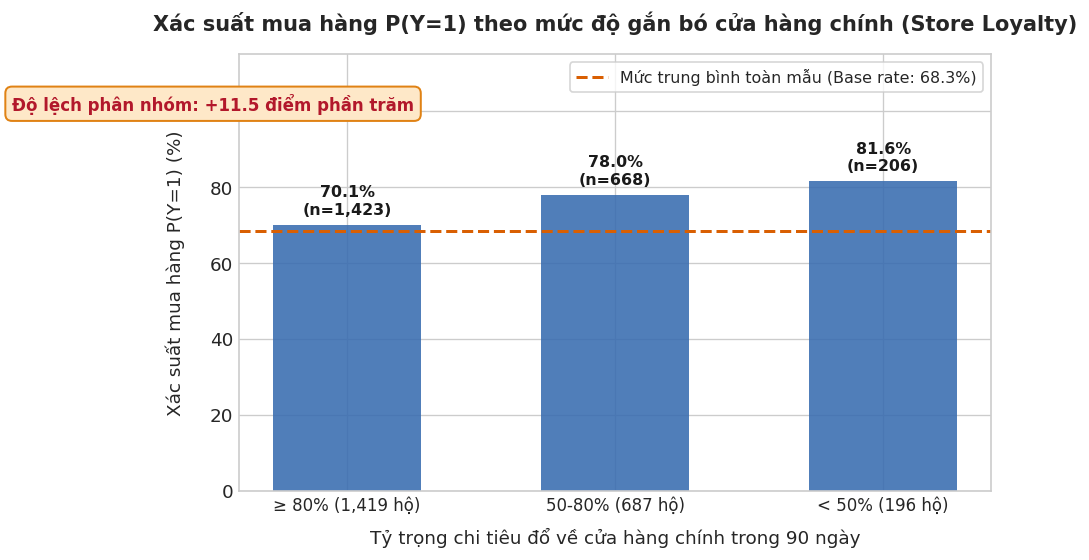

In [13]:
# Truy vấn dữ liệu Store Loyalty tại t0 = 450
q_loyalty = f"""
WITH store_spend AS (
    SELECT household_key, STORE_ID, SUM(basket_spend) AS spend
    FROM baskets
    WHERE DAY > {t0 - 90} AND DAY <= {t0}
    GROUP BY household_key, STORE_ID
),
tot_spend AS (
    SELECT household_key, SUM(spend) AS tot, MAX(spend) AS primary_spend
    FROM store_spend
    GROUP BY household_key
),
loyalty_calc AS (
    SELECT h.household_key,
           ts.primary_spend / NULLIF(ts.tot, 0) AS loyalty_ratio
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN tot_spend ts ON h.household_key = ts.household_key
),
loyalty_binned AS (
    SELECT household_key,
           CASE
               WHEN loyalty_ratio IS NULL THEN '0 giỏ (198 hộ)'
               WHEN loyalty_ratio >= 0.80 THEN '≥ 80% (1,419 hộ)'
               WHEN loyalty_ratio >= 0.50 THEN '50-80% (687 hộ)'
               ELSE '< 50% (196 hộ)'
           END AS loyalty_group,
           CASE
               WHEN loyalty_ratio IS NULL THEN 0
               WHEN loyalty_ratio >= 0.80 THEN 1
               WHEN loyalty_ratio >= 0.50 THEN 2
               ELSE 3
           END AS grp_order
    FROM loyalty_calc
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT lb.loyalty_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM loyalty_binned lb
LEFT JOIN target t ON lb.household_key = t.household_key
WHERE lb.grp_order > 0
GROUP BY lb.loyalty_group, lb.grp_order
ORDER BY lb.grp_order
"""
df_loyalty = con.execute(q_loyalty).df()
display(df_loyalty)

plot_gold_standard(df_loyalty, 'loyalty_group', 'p_y1', 'n',
                   title="Xác suất mua hàng P(Y=1) theo mức độ gắn bó cửa hàng chính (Store Loyalty)",
                   xlabel="Tỷ trọng chi tiêu đổ về cửa hàng chính trong 90 ngày",
                   fig_name="08_p_y1_store_loyalty.png",
                   delta_idx=(0, -1), delta_label="Độ lệch phân nhóm",
                   bar_color='#386cb0')


### 3.9. Đặc trưng 9: Demographics — Tín Hiệu Phân Tách Của Nhóm UNKNOWN vs $P(Y=1)$
Kiểm định quy mô hộ gia đình (`HOUSEHOLD_SIZE`) và sự khác biệt rõ rệt của nhóm không khai báo thông tin (`UNKNOWN`, $n = 1,699$).


,demo_group,n,p_y1
0,1 người,255,91.8
1,2 người,318,90.9
2,3 người,109,92.7
3,4 người,53,88.7
4,5+ người,66,89.4
5,UNKNOWN (Khuyết),1699,57.4


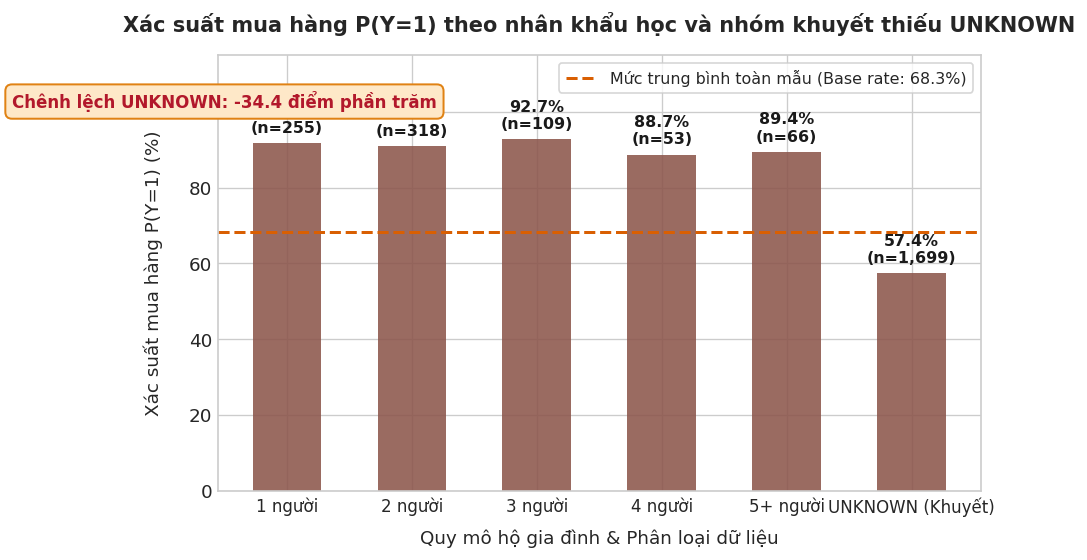

In [14]:
# Truy vấn dữ liệu Demographics tại t0 = 450
q_demo = f"""
WITH demo_binned AS (
    SELECT h.household_key,
           CASE
               WHEN d.classification_4 = '1' THEN '1 người'
               WHEN d.classification_4 = '2' THEN '2 người'
               WHEN d.classification_4 = '3' THEN '3 người'
               WHEN d.classification_4 = '4' THEN '4 người'
               WHEN d.classification_4 = '5+' THEN '5+ người'
               ELSE 'UNKNOWN (Khuyết)'
           END AS demo_group,
           CASE
               WHEN d.classification_4 = '1' THEN 1
               WHEN d.classification_4 = '2' THEN 2
               WHEN d.classification_4 = '3' THEN 3
               WHEN d.classification_4 = '4' THEN 4
               WHEN d.classification_4 = '5+' THEN 5
               ELSE 6
           END AS grp_order
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN df_demo d ON h.household_key = d.household_key
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT db.demo_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM demo_binned db
LEFT JOIN target t ON db.household_key = t.household_key
GROUP BY db.demo_group, db.grp_order
ORDER BY db.grp_order
"""
df_demo_res = con.execute(q_demo).df()
display(df_demo_res)

plot_gold_standard(df_demo_res, 'demo_group', 'p_y1', 'n',
                   title="Xác suất mua hàng P(Y=1) theo nhân khẩu học và nhóm khuyết thiếu UNKNOWN",
                   xlabel="Quy mô hộ gia đình & Phân loại dữ liệu",
                   fig_name="09_p_y1_demographics.png",
                   delta_idx=(0, -1), delta_label="Chênh lệch UNKNOWN",
                   bar_color='#8c564b')


---
## 4. Ma Trận Chuyển Giao Đặc Trưng Sang Giai Đoạn Mô Hình Hóa

Toàn bộ 9 nhóm phát hiện thực nghiệm trên được đúc kết thành hệ thống 28 đặc trưng trong pipeline `src/features/feature_builder.py`.

| Nhóm Đặc Trưng | Cửa Sổ Tính Toán | Biến Tiêu Biểu | Quan Hệ $Y$ | Ý Nghĩa Vật Lý / Vai Trò Trong Mô Hình |
| :--- | :---: | :--- | :---: | :--- |
| **1. Recency** | 711d | `days_since_last_basket`, `urgency_ratio` | Nghịch (-) | Đo lường độ trễ từ chuyến đi cuối so với chu kỳ cá nhân |
| **2. Frequency** | 90d | `baskets_count_90d`, `freq_momentum` | Đồng (+) | Tần suất mua sắm gần và gia tốc đi chợ (30d vs 90d) |
| **3. Spend & AOV** | 90d | `spend_90d`, `aov_90d`, `spend_trend` | Đồng (+) | Quy mô dòng tiền tích lũy và giá trị giỏ hàng điển hình |
| **4. Breadth** | 90d | `department_breadth_90d`, `avg_items` | Đồng (+) | Độ phủ ngành hàng đã mua; proxy của mức độ gắn kết |
| **5. Perishables** | 90d | `days_since_perishable`, `perish_ratio` | Nghịch (-) | Tín hiệu cạn kiệt đồ tươi sống thúc đẩy chuyến đi kế tiếp |
| **6. Campaigns** | Tại $t_0$ | `is_targeted_type_A`, `type_B`, `type_C` | Đồng (+) | Trạng thái nhắm mục tiêu của chiến dịch tiếp thị kích hoạt |
| **7. Coupons** | 180d | `coupon_redemptions_180d` | Đồng (+) | Độ nhạy cảm khuyến mãi và lịch sử đổi phiếu ưu đãi |
| **8. Store Loyalty** | 90d | `primary_store_spend_share`, `store_id` | Phân nhóm | Tỷ trọng chi tiêu đổ về cửa hàng chính của hộ gia đình |
| **9. Demographics** | Cố định | `household_size`, `income`, `UNKNOWN` | Phân nhóm | Phân tách nhóm hộ có khai báo và nhóm khách vãng lai |

> **Bảo Đảm Kỹ Thuật (Point-in-Time Discipline):** 100% đặc trưng tuân thủ ranh giới $DAY \le t_0$, tuyệt đối không sử dụng thông tin tương lai, triệt tiêu hoàn toàn rủi ro rò rỉ dữ liệu (data leakage).


---
## 5. Phụ Lục: Góc Nhìn Chiến Lược Bán Lẻ & Quản Trị Vận Hành (Business Appendix)

Phần này phân tích 4 khía cạnh kinh doanh quan trọng, hỗ trợ ban lãnh đạo chuỗi siêu thị trong việc hoạch định chính sách CRM, ngân sách khuyến mãi và tối ưu ca trực vận hành.

### 5.1. Phụ Lục 1: Mức Độ Tập Trung Doanh Thu & Kiểm Định Pareto
Khảo sát phân hóa doanh số qua tổng chi tiêu \$8.06 Triệu USD của 2,500 hộ gia đình trong 2 năm.


C:\Users\kienn\AppData\Local\Temp\ipykernel_20280\398002855.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  gini = (1.0 - 2.0 * np.trapz(cum_rev[::-1], cum_hh[::-1]))


📊 PHÂN HÓA DOANH THU & HỆ SỐ GINI:
 - Tổng doanh thu 2 năm: $8,057,463.00 USD
 - Hệ số Gini: 2.503
 - Top 10% hộ gia đình đóng góp: 34.29% doanh thu
 - Top 20% hộ gia đình đóng góp: 53.05% doanh thu ($4,274,190 USD)
 - Cần 44.0% số hộ gia đình để tích lũy 80% doanh thu


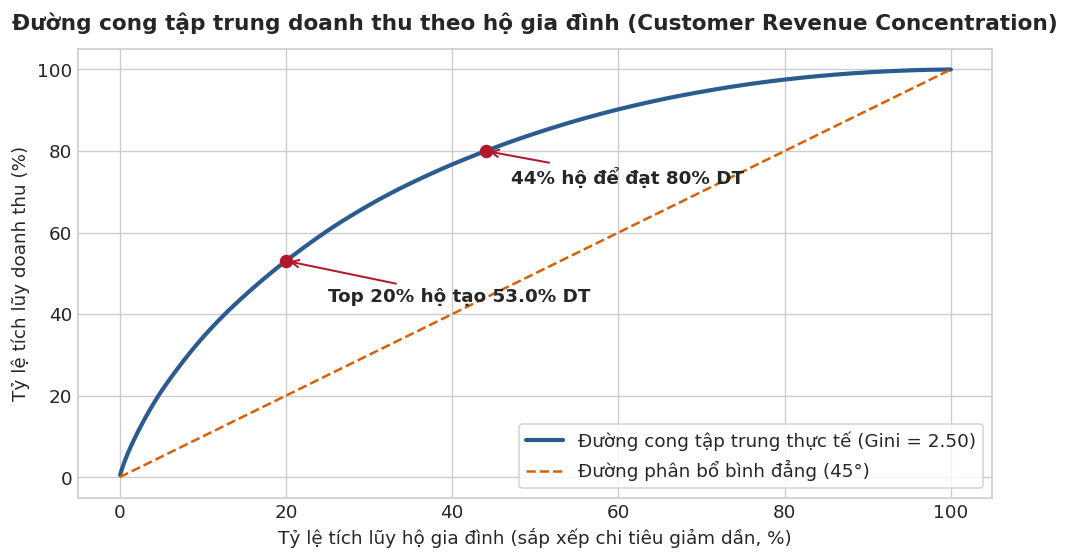

In [15]:
# 1. Tính toán tổng chi tiêu của từng hộ gia đình
hh_spend = baskets.groupby('household_key')['basket_spend'].sum().sort_values(ascending=False).values
tot_rev = hh_spend.sum()
cum_rev = np.cumsum(hh_spend) / tot_rev
cum_hh = np.arange(1, len(hh_spend) + 1) / len(hh_spend)

# Hệ số Gini
gini = (1.0 - 2.0 * np.trapz(cum_rev[::-1], cum_hh[::-1]))

top10_share = cum_rev[int(len(cum_hh) * 0.10) - 1] * 100.0
top20_share = cum_rev[int(len(cum_hh) * 0.20) - 1] * 100.0
hh_for_80 = cum_hh[np.where(cum_rev >= 0.80)[0][0]] * 100.0

print(f"📊 PHÂN HÓA DOANH THU & HỆ SỐ GINI:")
print(f" - Tổng doanh thu 2 năm: ${tot_rev:,.2f} USD")
print(f" - Hệ số Gini: {gini:.3f}")
print(f" - Top 10% hộ gia đình đóng góp: {top10_share:.2f}% doanh thu")
print(f" - Top 20% hộ gia đình đóng góp: {top20_share:.2f}% doanh thu (${tot_rev * top20_share / 100:,.0f} USD)")
print(f" - Cần {hh_for_80:.1f}% số hộ gia đình để tích lũy 80% doanh thu")

# Vẽ đường cong tập trung doanh thu
plt.figure(figsize=(8.5, 4.8))
plt.plot(cum_hh * 100.0, cum_rev * 100.0, color='#2b5c8f', linewidth=2.5,
         label=f'Đường cong tập trung thực tế (Gini = {gini:.2f})')
plt.plot([0, 100], [0, 100], color='#d95f02', linestyle='--', linewidth=1.5,
         label='Đường phân bổ bình đẳng (45°)')

plt.scatter([20.0, hh_for_80], [top20_share, 80.0], color='#b2182b', s=50, zorder=5)
plt.annotate(f"Top 20% hộ tạo {top20_share:.1f}% DT", xy=(20.0, top20_share), xytext=(25, top20_share - 10),
             arrowprops=dict(arrowstyle="->", color='#b2182b', lw=1.2), fontweight='bold')
plt.annotate(f"{hh_for_80:.0f}% hộ để đạt 80% DT", xy=(hh_for_80, 80.0), xytext=(hh_for_80 + 3, 72),
             arrowprops=dict(arrowstyle="->", color='#b2182b', lw=1.2), fontweight='bold')

plt.title("Đường cong tập trung doanh thu theo hộ gia đình (Customer Revenue Concentration)", pad=12)
plt.xlabel("Tỷ lệ tích lũy hộ gia đình (sắp xếp chi tiêu giảm dần, %)")
plt.ylabel("Tỷ lệ tích lũy doanh thu (%)")
plt.legend(frameon=True, facecolor='white', loc='lower right')
plt.tight_layout()
plt.savefig(FIG_DIR / '19_clv_pareto_distribution.png', dpi=150)
plt.show()


### 5.2. Phụ Lục 2: Cấu Trúc Chiết Khấu Hai Tầng Trong Bán Lẻ
Đối sánh giữa giảm giá niêm yết tại quầy của siêu thị (`RETAIL_DISC`) và giảm giá qua phiếu coupon (`COUPON_DISC`).


📊 ĐỐI SÁNH NGÂN SÁCH CHIẾT KHẤU:
 - Giảm giá quầy (RETAIL_DISC): $1,398,334.84 (14.72% doanh thu gộp, phủ 83.67% giỏ hàng)
 - Giảm giá coupon (COUPON_DISC): $42,611.54 (0.45% doanh thu gộp, phủ 6.08% giỏ hàng)
 - Tỷ số chiết khấu quầy / coupon: 32.8 lần


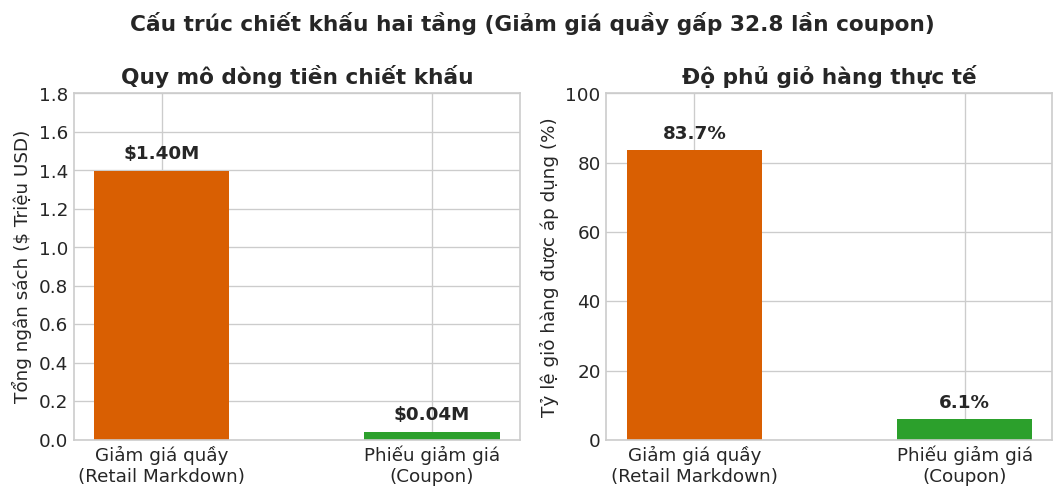

In [16]:
# Tính toán ngân sách chiết khấu và độ phủ giỏ hàng
q_disc = """
SELECT
    SUM(RETAIL_DISC) AS tot_retail_disc,
    SUM(COUPON_DISC) AS tot_coupon_disc,
    SUM(SALES_VALUE) AS tot_sales_net
FROM df_trans
"""
res_disc = con.execute(q_disc).fetchone()
tot_ret = abs(res_disc[0])
tot_coup = abs(res_disc[1])
tot_gross = res_disc[2] + tot_ret + tot_coup

# Độ phủ giỏ hàng
q_cov = """
SELECT
    COUNT(*) AS tot_baskets,
    COUNT(CASE WHEN retail_discount < 0 THEN 1 END) AS baskets_with_retail,
    COUNT(CASE WHEN coupon_discount < 0 THEN 1 END) AS baskets_with_coupon
FROM baskets
"""
res_cov = con.execute(q_cov).fetchone()
cov_ret = res_cov[1] * 100.0 / res_cov[0]
cov_coup = res_cov[2] * 100.0 / res_cov[0]
ratio = tot_ret / tot_coup

print("📊 ĐỐI SÁNH NGÂN SÁCH CHIẾT KHẤU:")
print(f" - Giảm giá quầy (RETAIL_DISC): ${tot_ret:,.2f} ({tot_ret * 100.0 / tot_gross:.2f}% doanh thu gộp, phủ {cov_ret:.2f}% giỏ hàng)")
print(f" - Giảm giá coupon (COUPON_DISC): ${tot_coup:,.2f} ({tot_coup * 100.0 / tot_gross:.2f}% doanh thu gộp, phủ {cov_coup:.2f}% giỏ hàng)")
print(f" - Tỷ số chiết khấu quầy / coupon: {ratio:.1f} lần")

# Vẽ biểu đồ đối sánh ngân sách chiết khấu
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.2))

# Cột 1: Ngân sách
bars1 = ax1.bar(['Giảm giá quầy\n(Retail Markdown)', 'Phiếu giảm giá\n(Coupon)'],
                [tot_ret / 1e6, tot_coup / 1e6], color=['#d95f02', '#2ca02c'], width=0.5)
ax1.set_ylabel("Tổng ngân sách ($ Triệu USD)")
ax1.set_title("Quy mô dòng tiền chiết khấu")
for b in bars1:
    h = b.get_height()
    ax1.text(b.get_x() + b.get_width() / 2, h + 0.04, f"${h:.2f}M", ha='center', va='bottom', fontweight='bold')
ax1.set_ylim(0, 1.8)

# Cột 2: Độ phủ giỏ hàng
bars2 = ax2.bar(['Giảm giá quầy\n(Retail Markdown)', 'Phiếu giảm giá\n(Coupon)'],
                [cov_ret, cov_coup], color=['#d95f02', '#2ca02c'], width=0.5)
ax2.set_ylabel("Tỷ lệ giỏ hàng được áp dụng (%)")
ax2.set_title("Độ phủ giỏ hàng thực tế")
for b in bars2:
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width() / 2, h + 2.0, f"{h:.1f}%", ha='center', va='bottom', fontweight='bold')
ax2.set_ylim(0, 100)

plt.suptitle(f"Cấu trúc chiết khấu hai tầng (Giảm giá quầy gấp {ratio:.1f} lần coupon)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / '20_markdown_vs_coupon_spend.png', dpi=150)
plt.show()


### 5.3. Phụ Lục 3: Tỷ Trọng & Hiệu Suất Của Nhãn Hàng Riêng (Private Label)
Đánh giá hiệu suất của nhãn hàng riêng siêu thị so với thương hiệu quốc gia (National Brand).


📊 HIỆU SUẤT NHÃN HÀNG RIÊNG (PRIVATE LABEL) VS THƯƠNG HIỆU QUỐC GIA:


,BRAND,sku_count,sku_pct,spend_pct,units_pct,spend_sku_idx
0,Private,13814,14.960093,27.766324,99.078641,1.856026
1,National,78525,85.039907,72.233676,0.921359,0.849409


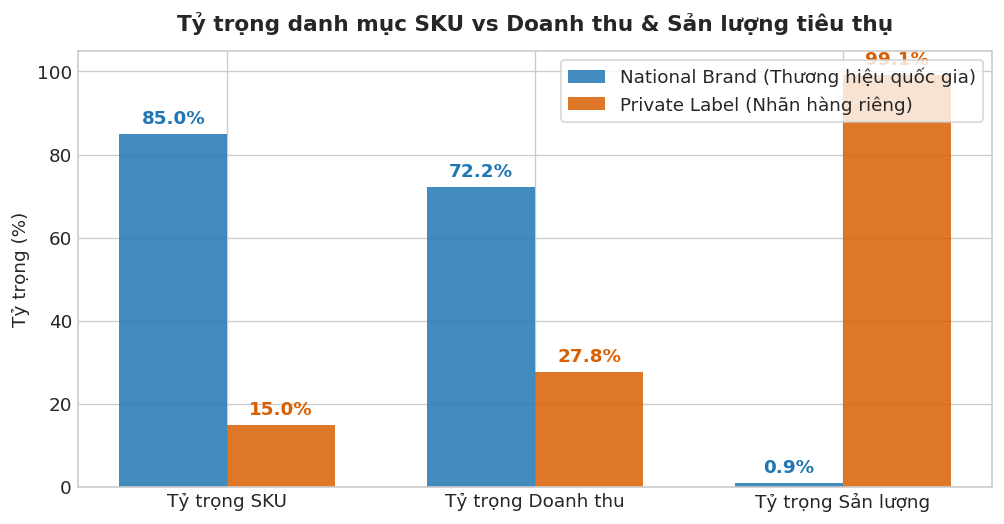

In [17]:
# Truy vấn dữ liệu nhãn hàng riêng
q_brand = """
SELECT
    p.BRAND,
    COUNT(DISTINCT p.PRODUCT_ID) AS sku_count,
    SUM(t.SALES_VALUE) AS tot_spend,
    SUM(t.QUANTITY) AS tot_units
FROM df_trans t
JOIN df_prod p ON t.PRODUCT_ID = p.PRODUCT_ID
GROUP BY p.BRAND
"""
df_brand = con.execute(q_brand).df()

tot_skus = df_brand['sku_count'].sum()
tot_rev_brand = df_brand['tot_spend'].sum()
tot_units_brand = df_brand['tot_units'].sum()

df_brand['sku_pct'] = df_brand['sku_count'] * 100.0 / tot_skus
df_brand['spend_pct'] = df_brand['tot_spend'] * 100.0 / tot_rev_brand
df_brand['units_pct'] = df_brand['tot_units'] * 100.0 / tot_units_brand
df_brand['spend_sku_idx'] = df_brand['spend_pct'] / df_brand['sku_pct']

print("📊 HIỆU SUẤT NHÃN HÀNG RIÊNG (PRIVATE LABEL) VS THƯƠNG HIỆU QUỐC GIA:")
display(df_brand[['BRAND', 'sku_count', 'sku_pct', 'spend_pct', 'units_pct', 'spend_sku_idx']])

# Vẽ biểu đồ đối sánh
fig, ax = plt.subplots(figsize=(8.5, 4.5))
metrics = ['Tỷ trọng SKU', 'Tỷ trọng Doanh thu', 'Tỷ trọng Sản lượng']
private_vals = [df_brand[df_brand['BRAND']=='Private']['sku_pct'].iloc[0],
                df_brand[df_brand['BRAND']=='Private']['spend_pct'].iloc[0],
                df_brand[df_brand['BRAND']=='Private']['units_pct'].iloc[0]]
national_vals = [df_brand[df_brand['BRAND']=='National']['sku_pct'].iloc[0],
                 df_brand[df_brand['BRAND']=='National']['spend_pct'].iloc[0],
                 df_brand[df_brand['BRAND']=='National']['units_pct'].iloc[0]]

x_m = np.arange(len(metrics))
width = 0.35

b_nat = ax.bar(x_m - width / 2, national_vals, width, label='National Brand (Thương hiệu quốc gia)', color='#1f77b4', alpha=0.85)
b_priv = ax.bar(x_m + width / 2, private_vals, width, label='Private Label (Nhãn hàng riêng)', color='#d95f02', alpha=0.85)

for b in b_nat:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width() / 2, h + 1.5, f"{h:.1f}%", ha='center', va='bottom', fontweight='bold', color='#1f77b4')
for b in b_priv:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width() / 2, h + 1.5, f"{h:.1f}%", ha='center', va='bottom', fontweight='bold', color='#d95f02')

ax.set_xticks(x_m, metrics, fontweight='medium')
ax.set_ylim(0, 105)
ax.set_ylabel("Tỷ trọng (%)")
ax.set_title("Tỷ trọng danh mục SKU vs Doanh thu & Sản lượng tiêu thụ", pad=12)
ax.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.savefig(FIG_DIR / '21_private_label_penetration.png', dpi=150)
plt.show()


### 5.4. Phụ Lục 4: Phân Phối Thời Gian Mua Sắm Theo Chu Kỳ Ngày & Giờ
Mô tả nhịp điệu vi mô theo chu kỳ ngày (`DAY mod 7`) và khung giờ mua sắm trong ngày.


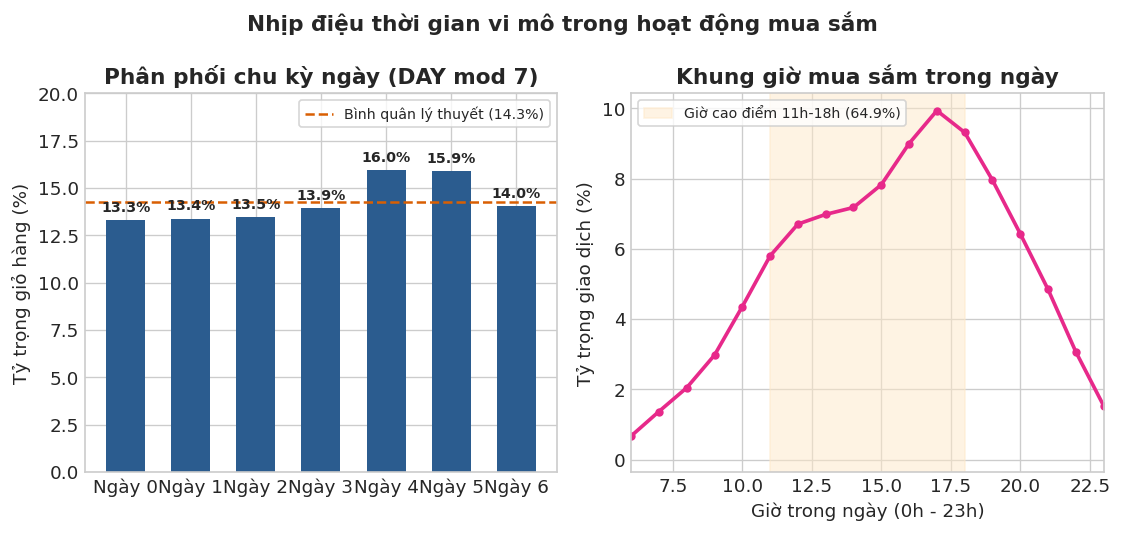

In [18]:
# 1. Phân phối chu kỳ ngày (DAY mod 7)
q_day = """
SELECT
    DAY % 7 AS day_mod_7,
    COUNT(*) AS basket_count
FROM baskets
GROUP BY day_mod_7
ORDER BY day_mod_7
"""
df_day = con.execute(q_day).df()
tot_b = df_day['basket_count'].sum()
df_day['pct'] = df_day['basket_count'] * 100.0 / tot_b

# 2. Phân phối khung giờ mua sắm trong ngày
baskets_hour = baskets.copy()
baskets_hour['hour'] = baskets_hour['trans_time'] // 100
hourly_dist = baskets_hour.groupby('hour')['BASKET_ID'].count()
hourly_pct = hourly_dist * 100.0 / len(baskets_hour)

# Vẽ biểu đồ kết hợp
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 4.5))

# Biểu đồ chu kỳ ngày
bars_d = ax1.bar([f"Ngày {d}" for d in df_day['day_mod_7']], df_day['pct'], color='#2b5c8f', width=0.6)
ax1.axhline(100.0 / 7.0, color='#d95f02', linestyle='--', linewidth=1.5, label='Bình quân lý thuyết (14.3%)')
for b in bars_d:
    h = b.get_height()
    ax1.text(b.get_x() + b.get_width() / 2, h + 0.3, f"{h:.1f}%", ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax1.set_ylim(0, 20)
ax1.set_title("Phân phối chu kỳ ngày (DAY mod 7)")
ax1.set_ylabel("Tỷ trọng giỏ hàng (%)")
ax1.legend(frameon=True, facecolor='white', loc='upper right', fontsize=8.5)

# Biểu đồ khung giờ
ax2.plot(hourly_pct.index, hourly_pct.values, color='#e7298a', marker='o', linewidth=2.2, markersize=4)
ax2.axvspan(11, 18, color='#fee8c8', alpha=0.5, label='Giờ cao điểm 11h-18h (64.9%)')
ax2.set_title("Khung giờ mua sắm trong ngày")
ax2.set_xlabel("Giờ trong ngày (0h - 23h)")
ax2.set_ylabel("Tỷ trọng giao dịch (%)")
ax2.set_xlim(6, 23)
ax2.legend(frameon=True, facecolor='white', loc='upper left', fontsize=8.5)

plt.suptitle("Nhịp điệu thời gian vi mô trong hoạt động mua sắm", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / '03_temporal_combined_rhythm.png', dpi=150)
plt.show()


---
## 6. Tổng Kết Giai Đoạn Khám Phá Dữ Liệu & Chuyển Giao Dự Án

Giai đoạn Khám phá Dữ liệu & Kiểm toán Chất lượng đã hoàn thành xuất sắc 3 sứ mệnh then chốt:

1. **Chuẩn hóa nền tảng sạch:** Khử toàn bộ 942 giỏ hàng hoàn/hủy/quẹt thẻ đơn lẻ $\le \$0$, khử 5,164 bản ghi coupon trùng lặp, bảo toàn đủ 2,500 hộ gia đình với danh mục `UNKNOWN` đại diện cho 68% hộ không khai báo thông tin.
2. **Xác lập cơ sở khoa học:** Chứng minh cửa sổ nhãn $\Delta t = 14$ ngày đạt độ ổn định cao (68.34% $\pm 1.04\%$), cân bằng tối ưu giữa chu kỳ tiêu dùng và năng lực vận hành CRM.
3. **Chuyển giao 28 đặc trưng Point-in-Time chất lượng cao:** 9 nhóm đặc trưng hành vi cốt lõi đã được kiểm định thực nghiệm và kiểm tra nghiêm ngặt về tính độc lập thời gian ($DAY \le t_0$), sẵn sàng làm đầu vào cho mô hình **LightGBM Calibrated Classifier**.
